# Audience segmentation with K-Means (v2)

This notebook segments 12,992 social media profiles by their interests, so marketing campaigns can be targeted at each segment.

It is a second pass on [`marketing.ipynb`](marketing.ipynb). In that first version, `sexo` was one-hot encoded and fed to K-Means together with the interest scores, and the three clusters it found turned out to be exactly the three values of `sexo`. Here the clustering is rebuilt on interest scores only, and the segments are compared against sex afterwards.

**Outline**

1. Data
2. What went wrong in v1
3. Feature choice
4. Choosing k
5. Final model and segment profiles
6. Projection in two dimensions
7. Segments versus sex
8. Stability
9. Saving the model
10. Limitations and next steps

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler

RANDOM_STATE = 45
N_INIT = 30  # many initialisations, so the result does not depend on a lucky seed
IMAGES = Path("../images")
IMAGES.mkdir(exist_ok=True)

# Chart style
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#a8a69f"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": BASELINE,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

## 1. Data

Each row is a profile: `sexo` (F, M or NE), `idade`, `numero_de_amigos` and 24 interest scores (sports, music and dance, appearance and shopping, brands). Column names are in Portuguese.

In [2]:
df = pd.read_csv("../dados/dados_mkt.csv")
INTEREST_COLS = [c for c in df.columns if c not in ("sexo", "idade", "numero_de_amigos")]

print(f"{df.shape[0]:,} profiles, {df.shape[1]} columns, {int(df.isna().sum().sum())} missing values")
print(f"{len(INTEREST_COLS)} interest columns")
df.head()

12,992 profiles, 27 columns, 0 missing values
24 interest columns


,sexo,idade,numero_de_amigos,basquete,futebol_americano,futebol,softbol,voleibol,natacao,animacao,beisebol,tenis,esportes,fofo,danca,banda,marcha,musica,rock,cabelo,vestido,shopping,compras,roupas,nossa_marca,marca_concorrente,bebidas
0,F,27,49,0,0,10,0,0,10,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,10
1,F,27,41,0,0,0,0,0,0,0,10,0,0,0,0,0,0,10,20,40,0,10,0,0,0,0,10
2,F,26,1,0,0,0,0,0,10,0,0,30,0,60,0,0,0,10,0,50,0,0,0,30,0,0,0
3,M,28,32,0,50,0,0,0,0,0,0,0,0,0,0,10,0,10,10,0,0,0,0,0,0,0,0
4,M,28,18,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,10,0,0,0


In [3]:
zero_share = (df[INTEREST_COLS] == 0).to_numpy().mean()
print(f"Share of interest scores equal to zero: {zero_share:.0%}")
df[["idade", "numero_de_amigos"]].describe().T[["min", "50%", "max", "mean", "std"]].round(1)

Share of interest scores equal to zero: 85%


,min,50%,max,mean,std
idade,21.0,27.0,30.0,26.9,1.2
numero_de_amigos,0.0,21.0,605.0,31.3,35.9


Interest scores are sparse: most profiles score zero on most interests. Age barely varies (standard deviation of about 1.2 years) and the number of friends is heavy-tailed, with a median of 21 and a maximum of 605.

## 2. What went wrong in v1

The same recipe as the first notebook: one-hot encode `sexo`, scale everything with Min-Max, run K-Means with k=3.

In [4]:
X_v1 = MinMaxScaler().fit_transform(pd.get_dummies(df, columns=["sexo"], dtype=float))
v1_labels = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init="auto").fit_predict(X_v1)

print("Silhouette score:", round(silhouette_score(X_v1, v1_labels), 3))
print("Adjusted Rand index against sexo:", round(adjusted_rand_score(df["sexo"], v1_labels), 3))
pd.crosstab(v1_labels, df["sexo"], rownames=["v1 cluster"])

Silhouette score: 0.745
Adjusted Rand index against sexo: 1.0


sexo,F,M,NE
v1 cluster,,,
0,9893,0,0
1,0,2160,0
2,0,0,939


Every v1 cluster contains a single value of `sexo`, so the adjusted Rand index is 1.0. After Min-Max scaling, the binary `sexo` columns span the full 0 to 1 range while most interest scores stay close to 0, so they dominate the distance calculation. The high silhouette score of v1 reflects that, not the strength of the interest segments.

## 3. Feature choice

v2 uses the 24 interest columns only. To check whether `idade` and `numero_de_amigos` help, the silhouette score is compared with and without them for k from 2 to 12.

In [5]:
WITH_AGE_FRIENDS = ["idade", "numero_de_amigos"] + INTEREST_COLS


def evaluate(columns, ks):
    X = MinMaxScaler().fit_transform(df[columns])
    rows = []
    for k in ks:
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(X)
        rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_)})
    return pd.DataFrame(rows).set_index("k")


ks = range(2, 13)
scores_interests = evaluate(INTEREST_COLS, ks)
scores_with_extras = evaluate(WITH_AGE_FRIENDS, ks)

pd.DataFrame({
    "interests only": scores_interests["silhouette"],
    "interests + age + friends": scores_with_extras["silhouette"],
}).round(3).T

k,2,3,4,5,6,7,8,9,10,11,12
interests only,0.378,0.348,0.352,0.315,0.141,0.147,0.145,0.151,0.153,0.141,0.142
interests + age + friends,0.185,0.181,0.185,0.189,0.090,0.097,0.096,0.097,0.098,0.098,0.102


Adding `idade` and `numero_de_amigos` lowers the silhouette score at every k (best value 0.189 against 0.378). Age carries little signal and the friends count is heavy-tailed, so after Min-Max scaling the extra columns mostly add noise. They are left out of the model.

## 4. Choosing k

Elbow method and silhouette score for k from 2 to 12, interests only. Each fit uses 30 initialisations (`N_INIT`), because a single run of K-Means can end in a poor local optimum; section 8 checks how stable the results are.

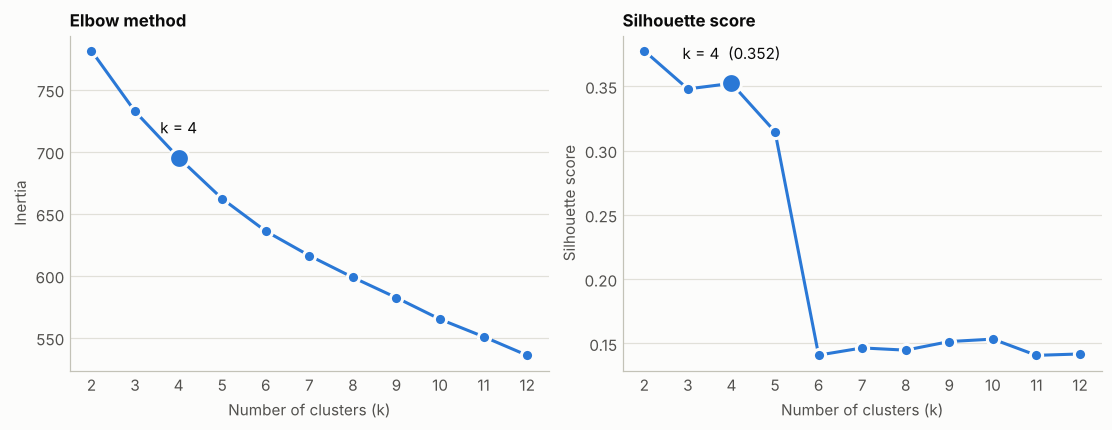

In [6]:
CHOSEN_K = 4

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
panels = [
    (axes[0], "inertia", "Elbow method", "Inertia"),
    (axes[1], "silhouette", "Silhouette score", "Silhouette score"),
]
for ax, column, title, ylabel in panels:
    values = scores_interests[column]
    ax.plot(values.index, values.values, color=BLUE, linewidth=2, solid_capstyle="round", zorder=2)
    ax.plot(values.index, values.values, "o", color=BLUE, markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2, zorder=3)
    ax.plot(CHOSEN_K, values[CHOSEN_K], "o", color=BLUE, markersize=13,
            markeredgecolor=SURFACE, markeredgewidth=2, zorder=4)
    label = f"k = {CHOSEN_K}" if column == "inertia" else f"k = {CHOSEN_K}  ({values[CHOSEN_K]:.3f})"
    ax.annotate(label, (CHOSEN_K, values[CHOSEN_K]), xytext=(0, 16), textcoords="offset points",
                ha="center", fontsize=10, color=INK)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(list(values.index))
    ax.tick_params(length=0)
    ax.grid(axis="x", visible=False)

fig.savefig(IMAGES / "k_selection.png", dpi=200)
plt.show()

The silhouette score is highest at k=2 (0.378), but two segments are too coarse to guide different campaigns. It stays at about 0.35 for k=3 and k=4 (0.348 and 0.352), drops to 0.315 at k=5 and falls sharply from k=6 onwards (0.141). The elbow is gradual and does not point to a single value.

k=4 is a judgment call: it keeps the silhouette of k=3 and separates one additional segment with a distinct profile, before the score collapses. k=3 and k=5 are defensible alternatives. The stability check in section 8 also rules out going beyond k=5.

## 5. Final model and segment profiles

Min-Max scaling and K-Means are wrapped in a single pipeline, so the same transformation is applied when new profiles are scored.

In [7]:
K = CHOSEN_K
pipeline = make_pipeline(MinMaxScaler(), KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=N_INIT))
df["segment"] = pipeline.fit_predict(df[INTEREST_COLS])

sizes = df["segment"].value_counts().sort_index()
pd.DataFrame({"profiles": sizes, "share": (sizes / len(df)).round(3)})

,profiles,share
segment,,
0,10177,0.783
1,702,0.054
2,1755,0.135
3,358,0.028


In [8]:
overall_mean = df[INTEREST_COLS].mean()
segment_means = df.groupby("segment")[INTEREST_COLS].mean()
lift = segment_means / overall_mean  # 1.0 = same as the overall average

for seg in segment_means.index:
    top = lift.loc[seg].sort_values(ascending=False).head(5).index
    print(f"Segment {seg}: " + ", ".join(f"{c} ({segment_means.loc[seg, c]:.1f}, {lift.loc[seg, c]:.1f}x)" for c in top))

Segment 0: marcha (0.5, 1.0x), tenis (0.9, 0.9x), banda (3.1, 0.9x), natacao (1.4, 0.9x), musica (7.4, 0.9x)
Segment 1: futebol_americano (27.2, 9.3x), beisebol (4.3, 3.6x), esportes (3.9, 2.4x), basquete (7.0, 2.3x), voleibol (2.9, 1.8x)
Segment 2: vestido (6.3, 4.7x), roupas (7.5, 4.4x), nossa_marca (3.0, 3.6x), marca_concorrente (2.0, 3.3x), cabelo (16.0, 3.2x)
Segment 3: animacao (27.9, 23.1x), marca_concorrente (1.5, 2.6x), nossa_marca (1.8, 2.1x), beisebol (2.0, 1.7x), compras (6.9, 1.7x)


Segments are named after what stands out in their profile. The ids come from K-Means and carry no meaning in themselves; the names below match the ids produced with `random_state=45`.

In [9]:
SEGMENT_NAMES = {0: "General", 1: "Sports", 2: "Fashion and shopping", 3: "Animation"}

# Guard against ids changing if the notebook is re-run with a different library version
assert sizes.idxmax() == 0
assert segment_means["futebol_americano"].idxmax() == 1
assert segment_means["compras"].idxmax() == 2
assert segment_means["animacao"].idxmax() == 3

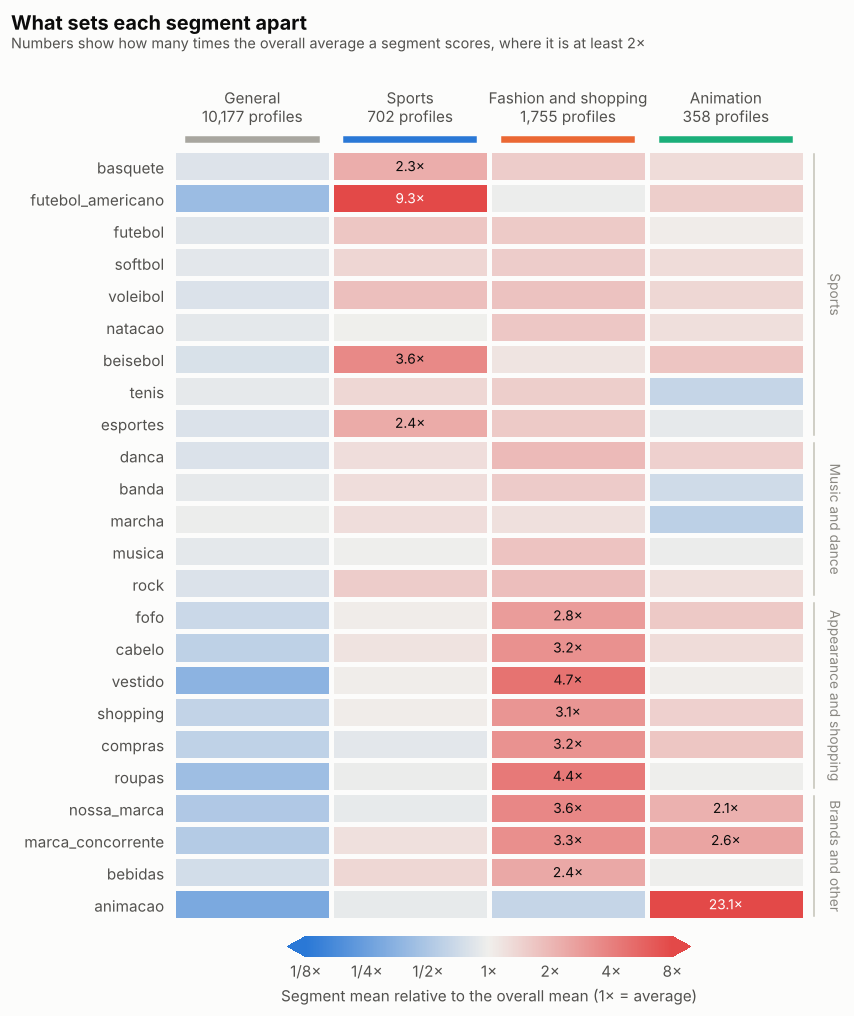

In [10]:
THEMES = {
    "Sports": ["basquete", "futebol_americano", "futebol", "softbol", "voleibol",
               "natacao", "beisebol", "tenis", "esportes"],
    "Music and dance": ["danca", "banda", "marcha", "musica", "rock"],
    "Appearance and shopping": ["fofo", "cabelo", "vestido", "shopping", "compras", "roupas"],
    "Brands and other": ["nossa_marca", "marca_concorrente", "bebidas", "animacao"],
}
ROW_ORDER = [c for cols in THEMES.values() for c in cols]
assert sorted(ROW_ORDER) == sorted(INTEREST_COLS)
SEGMENT_COLORS = {0: GRAY, 1: BLUE, 2: ORANGE, 3: AQUA}

cmap = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, "#f0efec", "#e34948"])
L = np.log2(lift[ROW_ORDER].T)  # rows: interests, columns: segments; log scale so 2x and 1/2x are symmetric

fig, ax = plt.subplots(figsize=(8.2, 9.4))
mesh = ax.pcolormesh(L.values, cmap=cmap, vmin=-3, vmax=3, edgecolors=SURFACE, linewidth=2)
ax.set_ylim(len(ROW_ORDER), 0)
ax.set_xlim(0, K)
ax.set_xticks(np.arange(K) + 0.5)
ax.set_yticks(np.arange(len(ROW_ORDER)) + 0.5)
ax.set_yticklabels(ROW_ORDER)
ax.set_xticklabels([f"{SEGMENT_NAMES[s]}\n{sizes[s]:,} profiles" for s in range(K)])
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.tick_params(axis="x", pad=16)
ax.tick_params(axis="y", pad=6)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)

# Segment identity chips above the column headers
for s in range(K):
    ax.add_patch(Rectangle((s + 0.08, -0.42), 0.84, 0.16, color=SEGMENT_COLORS[s],
                           clip_on=False, transform=ax.transData))

# Multiples shown only where a segment scores at least twice the overall average
for i, col in enumerate(ROW_ORDER):
    for j in range(K):
        value = lift.iloc[j][col]
        if value >= 2:
            r, g, b, _ = cmap((np.clip(np.log2(value), -3, 3) + 3) / 6)
            luminance = 0.2126 * r + 0.7152 * g + 0.0722 * b
            ax.text(j + 0.5, i + 0.5, f"{value:.1f}\u00d7", ha="center", va="center",
                    fontsize=9, color="#ffffff" if luminance < 0.5 else INK)

# Theme brackets on the right-hand side
start = 0
for theme, cols in THEMES.items():
    end = start + len(cols)
    ax.plot([K + 0.06, K + 0.06], [start + 0.12, end - 0.12], color=BASELINE, linewidth=1, clip_on=False)
    ax.text(K + 0.14, (start + end) / 2, theme, rotation=270, va="center", ha="left",
            color=MUTED, fontsize=9, clip_on=False)
    start = end

cbar = fig.colorbar(mesh, ax=ax, orientation="horizontal", fraction=0.025, pad=0.02, extend="both")
cbar.set_ticks([-3, -2, -1, 0, 1, 2, 3])
cbar.set_ticklabels(["1/8\u00d7", "1/4\u00d7", "1/2\u00d7", "1\u00d7", "2\u00d7", "4\u00d7", "8\u00d7"])
cbar.set_label("Segment mean relative to the overall mean (1\u00d7 = average)", color=INK_2)
cbar.outline.set_visible(False)
cbar.ax.tick_params(length=0, labelcolor=INK_2)

fig.text(0.02, 0.985, "What sets each segment apart", fontsize=13, fontweight="bold", ha="left", va="top")
fig.text(0.02, 0.962, "Numbers show how many times the overall average a segment scores, where it is at least 2\u00d7",
         fontsize=9.5, color=INK_2, ha="left", va="top")
fig.subplots_adjust(top=0.85, left=0.2, right=0.9, bottom=0.07)

fig.savefig(IMAGES / "segment_profiles.png", dpi=200)
plt.show()

In [11]:
segment_means.rename(index=SEGMENT_NAMES).T.round(1)

segment,General,Sports,Fashion and shopping,Animation
basquete,2.5,7.0,4.7,3.9
futebol_americano,1.2,27.2,2.8,4.4
futebol,2.2,4.2,4.1,2.6
softbol,1.6,2.5,2.8,2.3
voleibol,1.3,2.9,2.9,2.2
natacao,1.4,1.5,2.5,1.9
animacao,0.4,1.1,0.8,27.9
beisebol,0.9,4.3,1.4,2.0
tenis,0.9,1.4,1.5,0.6
esportes,1.3,3.9,2.6,1.5


**General** (10,177 profiles, 78.3%) scores below the overall average on 23 of the 24 interests. It is a diffuse group with no strong signal, the broadest and least targetable audience.

**Sports** (702 profiles, 5.4%) is led by American football, which averages 27.2 against 2.9 overall, followed by basketball (7.0) and baseball (4.3).

**Fashion and shopping** (1,755 profiles, 13.5%) leads on hair (16.0), music (14.5) and the shopping-related interests (`compras` 13.2, `shopping` 9.2, `roupas` 7.5, `vestido` 6.3). It also has the highest scores on both brand columns (`nossa_marca` 3.0, `marca_concorrente` 2.0).

**Animation** (358 profiles, 2.8%) is defined by `animacao`, which averages 27.9 against 1.2 overall, with above-average scores on `compras`, `fofo` and `cabelo`. It has the highest average number of friends (39.2 against 31.3 overall).

## 6. Projection in two dimensions

A PCA projection of the scaled interest scores, coloured by segment. The two components capture only part of the variance, so some overlap between segments is expected.

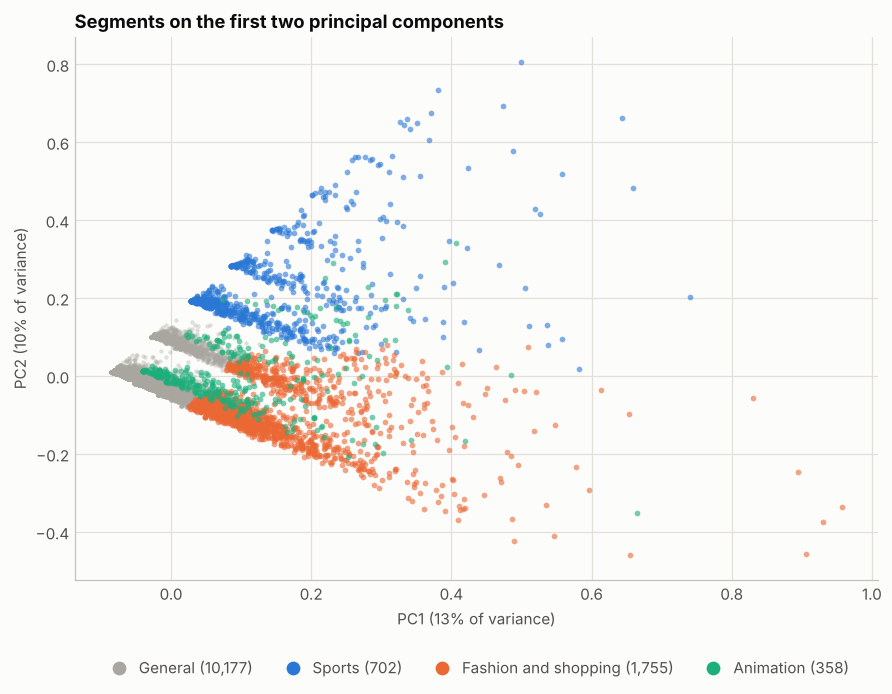

In [12]:
X_scaled = pipeline.named_steps["minmaxscaler"].transform(df[INTEREST_COLS])
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)
explained = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(8, 6.2), constrained_layout=True)
for seg in range(K):  # segment 0 is drawn first so the smaller segments stay visible on top
    mask = (df["segment"] == seg).to_numpy()
    ax.scatter(coords[mask, 0], coords[mask, 1], s=8 if seg == 0 else 14,
               alpha=0.35 if seg == 0 else 0.6, color=SEGMENT_COLORS[seg], linewidths=0)

handles = [
    Line2D([], [], marker="o", linestyle="", color=SEGMENT_COLORS[s], markersize=8,
           label=f"{SEGMENT_NAMES[s]} ({sizes[s]:,})")
    for s in range(K)
]
ax.legend(handles=handles, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4,
          handletextpad=0.3, columnspacing=1.6, labelcolor=INK_2)
ax.set_xlabel(f"PC1 ({explained[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.0%} of variance)")
ax.set_title("Segments on the first two principal components", loc="left", fontsize=12, fontweight="bold")
ax.tick_params(length=0)

fig.savefig(IMAGES / "pca_segments.png", dpi=200)
plt.show()

## 7. Segments versus sex

Sex was not used to build the segments. Comparing the two shows whether the segments are still a proxy for it.

In [13]:
print("Adjusted Rand index against sexo:", round(adjusted_rand_score(df["sexo"], df["segment"]), 3))

sex_mix = pd.crosstab(df["segment"].map(SEGMENT_NAMES), df["sexo"], normalize="index").mul(100).round(1)
sex_mix = sex_mix.reindex(list(SEGMENT_NAMES.values()))[["F", "M", "NE"]]
sex_mix.loc["All profiles"] = (df["sexo"].value_counts(normalize=True) * 100).round(1)[["F", "M", "NE"]]
sex_mix

Adjusted Rand index against sexo: -0.042


sexo,F,M,NE
segment,,,
General,74.3,18.1,7.6
Sports,58.3,36.2,5.6
Fashion and shopping,91.0,3.3,5.7
Animation,91.1,0.8,8.1
All profiles,76.1,16.6,7.2


In [14]:
df.groupby(df["segment"].map(SEGMENT_NAMES))[["idade", "numero_de_amigos"]].mean().reindex(
    list(SEGMENT_NAMES.values())).round(1)

,idade,numero_de_amigos
segment,,
General,26.9,30.0
Sports,26.8,33.2
Fashion and shopping,26.7,36.1
Animation,26.6,39.2


The adjusted Rand index is close to zero, so the segments are no longer a restatement of `sexo`. Sex still correlates with some interests (the Sports segment has the largest share of M profiles, the Fashion and shopping and Animation segments are about 91% F), which is expected: those are patterns in the interest scores themselves.

## 8. Stability

K-Means depends on its random initialisation, and a single run can end in a different local optimum. Two checks:

1. For each k, the model is refitted with five different seeds and each result is compared with the first one using the adjusted Rand index (1.0 means identical groups).
2. For the final model, the same comparison with ten seeds.

In [15]:
X_interests = MinMaxScaler().fit_transform(df[INTEREST_COLS])


def stability(k, seeds):
    runs = [KMeans(n_clusters=k, random_state=s, n_init=N_INIT).fit_predict(X_interests) for s in seeds]
    aris = [adjusted_rand_score(runs[0], other) for other in runs[1:]]
    return {"min ARI": min(aris), "mean ARI": np.mean(aris)}


pd.DataFrame({k: stability(k, range(5)) for k in range(2, 9)}).round(3)

,2,3,4,5,6,7,8
min ARI,0.993,0.988,0.995,0.981,0.552,0.747,0.548
mean ARI,0.994,0.989,0.997,0.984,0.887,0.869,0.786


In [16]:
final = stability(K, range(10))
print(f"k={K}, 10 seeds: min ARI {final['min ARI']:.3f}, mean ARI {final['mean ARI']:.3f}")

k=4, 10 seeds: min ARI 0.993, mean ARI 0.997


For k from 2 to 5 the segmentation is reproducible (minimum ARI above 0.98 across seeds). From k=6 it starts to depend on the seed, which is another reason to stay at k=4. The final model is stable: the minimum ARI over ten seeds is 0.993.

## 9. Saving the model

The pipeline is stored together with the feature list and the segment names, so the Streamlit app needs a single file.

In [17]:
artifact = {"pipeline": pipeline, "features": INTEREST_COLS, "segment_names": SEGMENT_NAMES}
joblib.dump(artifact, "segmentation_v2.pkl")

loaded = joblib.load("segmentation_v2.pkl")
assert (loaded["pipeline"].predict(df[loaded["features"]]) == df["segment"]).all()
print("Saved and reloaded: predictions match")

Saved and reloaded: predictions match


## 10. Limitations and next steps

- A silhouette score of about 0.35 means moderate structure: segments overlap, and most profiles fall into one diffuse segment. Interest scores come in steps of 10 and are mostly zero, which limits how cleanly K-Means can separate profiles.
- The choice of k=4 is a judgment call between several similar silhouette scores.
- Next steps worth trying: a log transform or a different scaler, Gaussian Mixture Models or hierarchical clustering for comparison, and validating the segments against real campaign response.